In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/ids-intrusion-csv/02-28-2018.csv
/kaggle/input/ids-intrusion-csv/03-01-2018.csv
/kaggle/input/ids-intrusion-csv/02-16-2018.csv
/kaggle/input/ids-intrusion-csv/02-15-2018.csv
/kaggle/input/ids-intrusion-csv/02-21-2018.csv
/kaggle/input/ids-intrusion-csv/03-02-2018.csv
/kaggle/input/ids-intrusion-csv/02-22-2018.csv
/kaggle/input/ids-intrusion-csv/02-20-2018.csv
/kaggle/input/ids-intrusion-csv/02-14-2018.csv
/kaggle/input/ids-intrusion-csv/02-23-2018.csv


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
%%time

df_d4 = pd.read_csv("", low_memory=False) #select one dataset from kaggle CIC-IDS-2018 csv for noise
df_d5 = pd.read_csv("", low_memory=False) #upload created dataset from wireshark and CICflowmeter



CPU times: user 2min 20s, sys: 25 s, total: 2min 45s
Wall time: 3min 32s


In [4]:
df_d4.drop(columns=['Flow ID', 'Src IP', 'Src Port', 'Dst IP'], axis=1,inplace=True)


In [5]:
def drop_unnecessary_column(df): 
    df.drop(columns="Timestamp", inplace=True)
    print (df.shape)
    return df

In [6]:
%%time

df_d4 = drop_unnecessary_column(df_d4)
df_d5 = drop_unnecessary_column(df_d5)


(7948748, 79)
(1048575, 79)
CPU times: user 1.16 s, sys: 900 ms, total: 2.06 s
Wall time: 2.06 s


In [7]:
def fix_data_type(df):
    
    df = df[df['Dst Port'] != 'Dst Port']
    
    df['Dst Port'] = df['Dst Port'].astype(int)
    df['Protocol'] = df['Protocol'].astype(int)
    df['Flow Duration'] = df['Flow Duration'].astype(int)
    df['Tot Fwd Pkts'] = df['Tot Fwd Pkts'].astype(int)
    df['Tot Bwd Pkts'] = df['Tot Bwd Pkts'].astype(int)
    df['TotLen Fwd Pkts'] = df['TotLen Fwd Pkts'].astype(int)
    df['TotLen Bwd Pkts'] = df['TotLen Bwd Pkts'].astype(int)
    df['Fwd Pkt Len Max'] = df['Fwd Pkt Len Max'].astype(int)
    df['Fwd Pkt Len Min'] = df['Fwd Pkt Len Min'].astype(int)
    df['Fwd Pkt Len Mean'] = df['Fwd Pkt Len Mean'].astype(float)
    df['Fwd Pkt Len Std'] = df['Fwd Pkt Len Std'].astype(float)
    df['Bwd Pkt Len Max'] = df['Bwd Pkt Len Max'].astype(int)
    df['Bwd Pkt Len Min'] = df['Bwd Pkt Len Min'].astype(int)
    df['Bwd Pkt Len Mean'] = df['Bwd Pkt Len Mean'].astype(float)
    df['Bwd Pkt Len Std'] = df['Bwd Pkt Len Std'].astype(float)
    df['Flow Byts/s'] = df['Flow Byts/s'].astype(float)
    df['Flow Pkts/s'] = df['Flow Pkts/s'].astype(float)
    df['Flow IAT Mean'] = df['Flow IAT Mean'].astype(float)
    df['Flow IAT Std'] = df['Flow IAT Std'].astype(float)
    df['Flow IAT Max'] = df['Flow IAT Max'].astype(int)
    df['Flow IAT Min'] = df['Flow IAT Min'].astype(int)
    df['Fwd IAT Tot'] = df['Fwd IAT Tot'].astype(int)
    df['Fwd IAT Mean'] = df['Fwd IAT Mean'].astype(float)
    df['Fwd IAT Std'] = df['Fwd IAT Std'].astype(float)
    df['Fwd IAT Max'] = df['Fwd IAT Max'].astype(int)
    df['Fwd IAT Min'] = df['Fwd IAT Min'].astype(int)
    df['Bwd IAT Tot'] = df['Bwd IAT Tot'].astype(int)
    df['Bwd IAT Mean'] = df['Bwd IAT Mean'].astype(float)
    df['Bwd IAT Std'] = df['Bwd IAT Std'].astype(float)
    df['Bwd IAT Max'] = df['Bwd IAT Max'].astype(int)
    df['Bwd IAT Min'] = df['Bwd IAT Min'].astype(int)
    df['Fwd PSH Flags'] = df['Fwd PSH Flags'].astype(int)
    df['Bwd PSH Flags'] = df['Bwd PSH Flags'].astype(int)
    df['Fwd URG Flags'] = df['Fwd URG Flags'].astype(int)
    df['Bwd URG Flags'] = df['Bwd URG Flags'].astype(int)
    df['Fwd Header Len'] = df['Fwd Header Len'].astype(int)
    df['Bwd Header Len'] = df['Bwd Header Len'].astype(int)
    df['Fwd Pkts/s'] = df['Fwd Pkts/s'].astype(float)
    df['Bwd Pkts/s'] = df['Bwd Pkts/s'].astype(float)
    df['Pkt Len Min'] = df['Pkt Len Min'].astype(int)
    df['Pkt Len Max'] = df['Pkt Len Max'].astype(int)
    df['Pkt Len Mean'] = df['Pkt Len Mean'].astype(float)
    df['Pkt Len Std'] = df['Pkt Len Std'].astype(float)
    df['Pkt Len Var'] = df['Pkt Len Var'].astype(float)
    df['FIN Flag Cnt'] = df['FIN Flag Cnt'].astype(int)
    df['SYN Flag Cnt'] = df['SYN Flag Cnt'].astype(int)
    df['RST Flag Cnt'] = df['RST Flag Cnt'].astype(int)
    df['PSH Flag Cnt'] = df['PSH Flag Cnt'].astype(int)
    df['ACK Flag Cnt'] = df['ACK Flag Cnt'].astype(int)
    df['URG Flag Cnt'] = df['URG Flag Cnt'].astype(int)
    df['CWE Flag Count'] = df['CWE Flag Count'].astype(int)
    df['ECE Flag Cnt'] = df['ECE Flag Cnt'].astype(int)
    df['Down/Up Ratio'] = df['Down/Up Ratio'].astype(int)
    df['Pkt Size Avg'] = df['Pkt Size Avg'].astype(float)
    df['Fwd Seg Size Avg'] = df['Fwd Seg Size Avg'].astype(float)
    df['Bwd Seg Size Avg'] = df['Bwd Seg Size Avg'].astype(float)
    df['Fwd Byts/b Avg'] = df['Fwd Byts/b Avg'].astype(int)
    df['Fwd Pkts/b Avg'] = df['Fwd Pkts/b Avg'].astype(int)
    df['Fwd Blk Rate Avg'] = df['Fwd Blk Rate Avg'].astype(int)
    df['Bwd Byts/b Avg'] = df['Bwd Byts/b Avg'].astype(int)
    df['Bwd Pkts/b Avg'] = df['Bwd Pkts/b Avg'].astype(int)
    df['Bwd Blk Rate Avg'] = df['Bwd Blk Rate Avg'].astype(int)
    df['Subflow Fwd Pkts'] = df['Subflow Fwd Pkts'].astype(int)
    df['Subflow Fwd Byts'] = df['Subflow Fwd Byts'].astype(int)
    df['Subflow Bwd Pkts'] = df['Subflow Bwd Pkts'].astype(int)
    df['Subflow Bwd Byts'] = df['Subflow Bwd Byts'].astype(int)
    df['Init Fwd Win Byts'] = df['Init Fwd Win Byts'].astype(int)
    df['Init Bwd Win Byts'] = df['Init Bwd Win Byts'].astype(int)
    df['Fwd Act Data Pkts'] = df['Fwd Act Data Pkts'].astype(int)
    df['Fwd Seg Size Min'] = df['Fwd Seg Size Min'].astype(int)
    df['Active Mean'] = df['Active Mean'].astype(float)
    df['Active Std'] = df['Active Std'].astype(float)
    df['Active Max'] = df['Active Max'].astype(int)
    df['Active Min'] = df['Active Min'].astype(int)
    df['Idle Mean'] = df['Idle Mean'].astype(float)
    df['Idle Std'] = df['Idle Std'].astype(float)
    df['Idle Max'] = df['Idle Max'].astype(int)
    df['Idle Min'] = df['Idle Min'].astype(int)
    
    return df

In [8]:
%%time

df_d4 = fix_data_type(df_d4)
df_d5 = fix_data_type(df_d5)


CPU times: user 3.89 s, sys: 3.19 s, total: 7.08 s
Wall time: 7.08 s


In [9]:
def drop_infinate_null(df):
    print (df.shape)

    # replace infinity value as null value
    df = df.replace(["Infinity", "infinity"], np.inf)
    df = df.replace([np.inf, -np.inf], np.nan)

    # drop all null values
    df.dropna(inplace=True)

    print (df.shape)
    
    return df


In [10]:
%%time

df_d4 = drop_infinate_null(df_d4)
df_d5 = drop_infinate_null(df_d5)



(7948748, 79)
(7889295, 79)
(1048575, 79)
(1048575, 79)
CPU times: user 10.3 s, sys: 5.76 s, total: 16.1 s
Wall time: 16.1 s


In [11]:
def generate_binary_label(df):
    # encode the target feature
    df['Threat'] = df['Label'].apply(lambda x: "Benign" if x == 'Benign' else "Malicious")
    print(df['Threat'].unique())
    print(df['Threat'].value_counts())
    return df

In [12]:
%%time

df_d4 = generate_binary_label(df_d4)
df_d5 = generate_binary_label(df_d5)


['Benign' 'Malicious']
Threat
Benign       7313104
Malicious     576191
Name: count, dtype: int64
['Benign' 'Malicious']
Threat
Malicious    687742
Benign       360833
Name: count, dtype: int64
CPU times: user 2.29 s, sys: 7.59 ms, total: 2.29 s
Wall time: 2.3 s


In [13]:
def reduce_mem_usage(props):
    start_mem_usg = props.memory_usage().sum() / 1024**2 
    print("Memory usage of properties dataframe is :",start_mem_usg," MB")
    NAlist = [] 
    for col in props.columns:
        if props[col].dtype != object:  

            IsInt = False
            mx = props[col].max()
            mn = props[col].min()
            
            if not np.isfinite(props[col]).all(): 
                NAlist.append(col)
                props[col].fillna(mn-1,inplace=True)  
                   
            asint = props[col].fillna(0).astype(np.int64)
            result = (props[col] - asint)
            result = result.sum()
            if result > -0.01 and result < 0.01:
                IsInt = True

            if IsInt:
                if mn >= 0:
                    if mx < 255:
                        props[col] = props[col].astype(np.uint8)
                    elif mx < 65535:
                        props[col] = props[col].astype(np.uint16)
                    elif mx < 4294967295:
                        props[col] = props[col].astype(np.uint32)
                    else:
                        props[col] = props[col].astype(np.uint64)
                else:
                    if mn > np.iinfo(np.int8).min and mx < np.iinfo(np.int8).max:
                        props[col] = props[col].astype(np.int8)
                    elif mn > np.iinfo(np.int16).min and mx < np.iinfo(np.int16).max:
                        props[col] = props[col].astype(np.int16)
                    elif mn > np.iinfo(np.int32).min and mx < np.iinfo(np.int32).max:
                        props[col] = props[col].astype(np.int32)
                    elif mn > np.iinfo(np.int64).min and mx < np.iinfo(np.int64).max:
                        props[col] = props[col].astype(np.int64)    
            
            else:
                props[col] = props[col].astype(np.float32)
    print("___MEMORY USAGE AFTER COMPLETION:___")
    mem_usg = props.memory_usage().sum() / 1024**2 
    print("Memory usage is: ",mem_usg," MB")
    print("This is ",100*mem_usg/start_mem_usg,"% of the initial size")
    return props, NAlist

In [14]:
%%time

df_d4, _ = reduce_mem_usage(df_d4)
df_d5, _ = reduce_mem_usage(df_d5)


Memory usage of properties dataframe is : 4875.4340744018555  MB
___MEMORY USAGE AFTER COMPLETION:___
Memory usage is:  1941.1450481414795  MB
This is  39.81481481481482 % of the initial size
Memory usage of properties dataframe is : 639.99951171875  MB
___MEMORY USAGE AFTER COMPLETION:___
Memory usage is:  238.99989414215088  MB
This is  37.343761950740394 % of the initial size
CPU times: user 11.1 s, sys: 4.01 s, total: 15.1 s
Wall time: 11.9 s


In [15]:
## https://www.researchgate.net/figure/Attack-Types-in-CSE-CIC-IDS2018-dataset_tbl1_333894962

mapping= {'SSH-Bruteforce': 'Brute-force',
          'FTP-BruteForce': 'Brute-force',
          ################ Brute-force 
          
          'Brute Force -XSS': 'Web attack',
          'Brute Force -Web': 'Web attack',
          'SQL Injection': 'Web attack',
          ################ Web attack 
          
          'DoS attacks-Hulk': 'DoS attack',
          'DoS attacks-SlowHTTPTest': 'DoS attack',
          'DoS attacks-Slowloris': 'DoS attack',
          'DoS attacks-GoldenEye': 'DoS attack',
          ################ DoS attack 
          
          'DDOS attack-HOIC': 'DDoS attack',
          'DDOS attack-LOIC-UDP': 'DDoS attack',
          'DDoS attacks-LOIC-HTTP': 'DDoS attack',
          ################ DDoS attack 
          
          'Bot': 'Botnet',
          ################ Botnet 
          
          'Infilteration': 'Infilteration',
          ################ Infilteration 
          
          'Benign': 'Benign',
          'Label': 'Benign',
          ################ Infilteration 
    }

def transform_multi_label(df):
    print(df['Label'].value_counts())
    df['Label'] = df['Label'].map(mapping) 
    return df

In [16]:
%%time

df_d4 = transform_multi_label(df_d4)
df_d5 = transform_multi_label(df_d5)


Label
Benign                    7313104
DDoS attacks-LOIC-HTTP     576191
Name: count, dtype: int64
Label
DDOS attack-HOIC        686012
Benign                  360833
DDOS attack-LOIC-UDP      1730
Name: count, dtype: int64
CPU times: user 977 ms, sys: 2.43 ms, total: 980 ms
Wall time: 973 ms


In [17]:
from imblearn.under_sampling import RandomUnderSampler

def balance_data(df):
    X=df.drop(["Label"], axis=1)
    y=df["Label"]
    
    rus = RandomUnderSampler()
    X_balanced, y_balanced = rus.fit_resample(X, y) 

    df = pd.concat([X_balanced, y_balanced], axis=1)
    del X, y, X_balanced, y_balanced
    print (df.shape)
    print(df['Label'].value_counts())
    
    return df

In [18]:
%%time

df_d4 = balance_data(df_d4)
df_d5 = balance_data(df_d5)

df_d5.head()

(1152382, 80)
Label
Benign         576191
DDoS attack    576191
Name: count, dtype: int64
(721666, 80)
Label
Benign         360833
DDoS attack    360833
Name: count, dtype: int64
CPU times: user 34.9 s, sys: 1.73 s, total: 36.7 s
Wall time: 36.7 s


,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Threat,Label
0,80,6,37953,5,3,135,127,135,0,27.0,...,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign
1,500,17,117573474,3,0,1500,0,500,500,500.0,...,0.0,0.0,0,0,58800000.0,23800000.0,75600000,42000000,Benign,Benign
2,500,17,117573474,3,0,1500,0,500,500,500.0,...,0.0,0.0,0,0,58800000.0,23800000.0,75600000,42000000,Benign,Benign
3,500,17,99743998,5,0,2500,0,500,500,500.0,...,4000290.0,0.0,4000290,4000290,31900000.0,37900000.0,75600000,7200397,Benign,Benign
4,500,17,99743999,5,0,2500,0,500,500,500.0,...,4000286.0,0.0,4000286,4000286,31900000.0,37900000.0,75600000,7200399,Benign,Benign


In [19]:
%%time
df_all = pd.concat([df_d4, df_d5], axis=0)
df_all.reset_index(drop=True, inplace=True)
del df_d4, df_d5




CPU times: user 116 ms, sys: 3.7 ms, total: 120 ms
Wall time: 118 ms


In [20]:
df_all['Label'] = df_all['Label'].replace({pd.NA: 'Benign', np.nan: 'Benign'})

df_all['Label'] = df_all['Label'].replace('nan', 'Benign')

print(df_all['Label'].value_counts())

Label
Benign         937024
DDoS attack    937024
Name: count, dtype: int64


In [21]:
%%time
variances = df_all.var(numeric_only=True)
constant_columns = variances[variances == 0].index
df_all = df_all.drop(constant_columns, axis=1)

print(constant_columns)
print (df_all.shape)

Index(['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count',
       'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg',
       'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg'],
      dtype='object')
(1874048, 70)
CPU times: user 1.3 s, sys: 2.89 ms, total: 1.3 s
Wall time: 830 ms


In [22]:
%%time
duplicates = set()
for i in range(0, len(df_all.columns)):
    col1 = df_all.columns[i]
    for j in range(i+1, len(df_all.columns)):
        col2 = df_all.columns[j]
        if(df_all[col1].equals(df_all[col2])):
            duplicates.add(col2)

CPU times: user 2.4 s, sys: 4.1 ms, total: 2.4 s
Wall time: 2.4 s


In [23]:
print (duplicates)
df_all.drop(duplicates, axis=1, inplace=True)
print (df_all.shape)

{'Subflow Bwd Pkts', 'Bwd Seg Size Avg', 'Subflow Fwd Pkts', 'Subflow Bwd Byts', 'Subflow Fwd Byts', 'SYN Flag Cnt', 'Fwd Seg Size Avg'}
(1874048, 63)


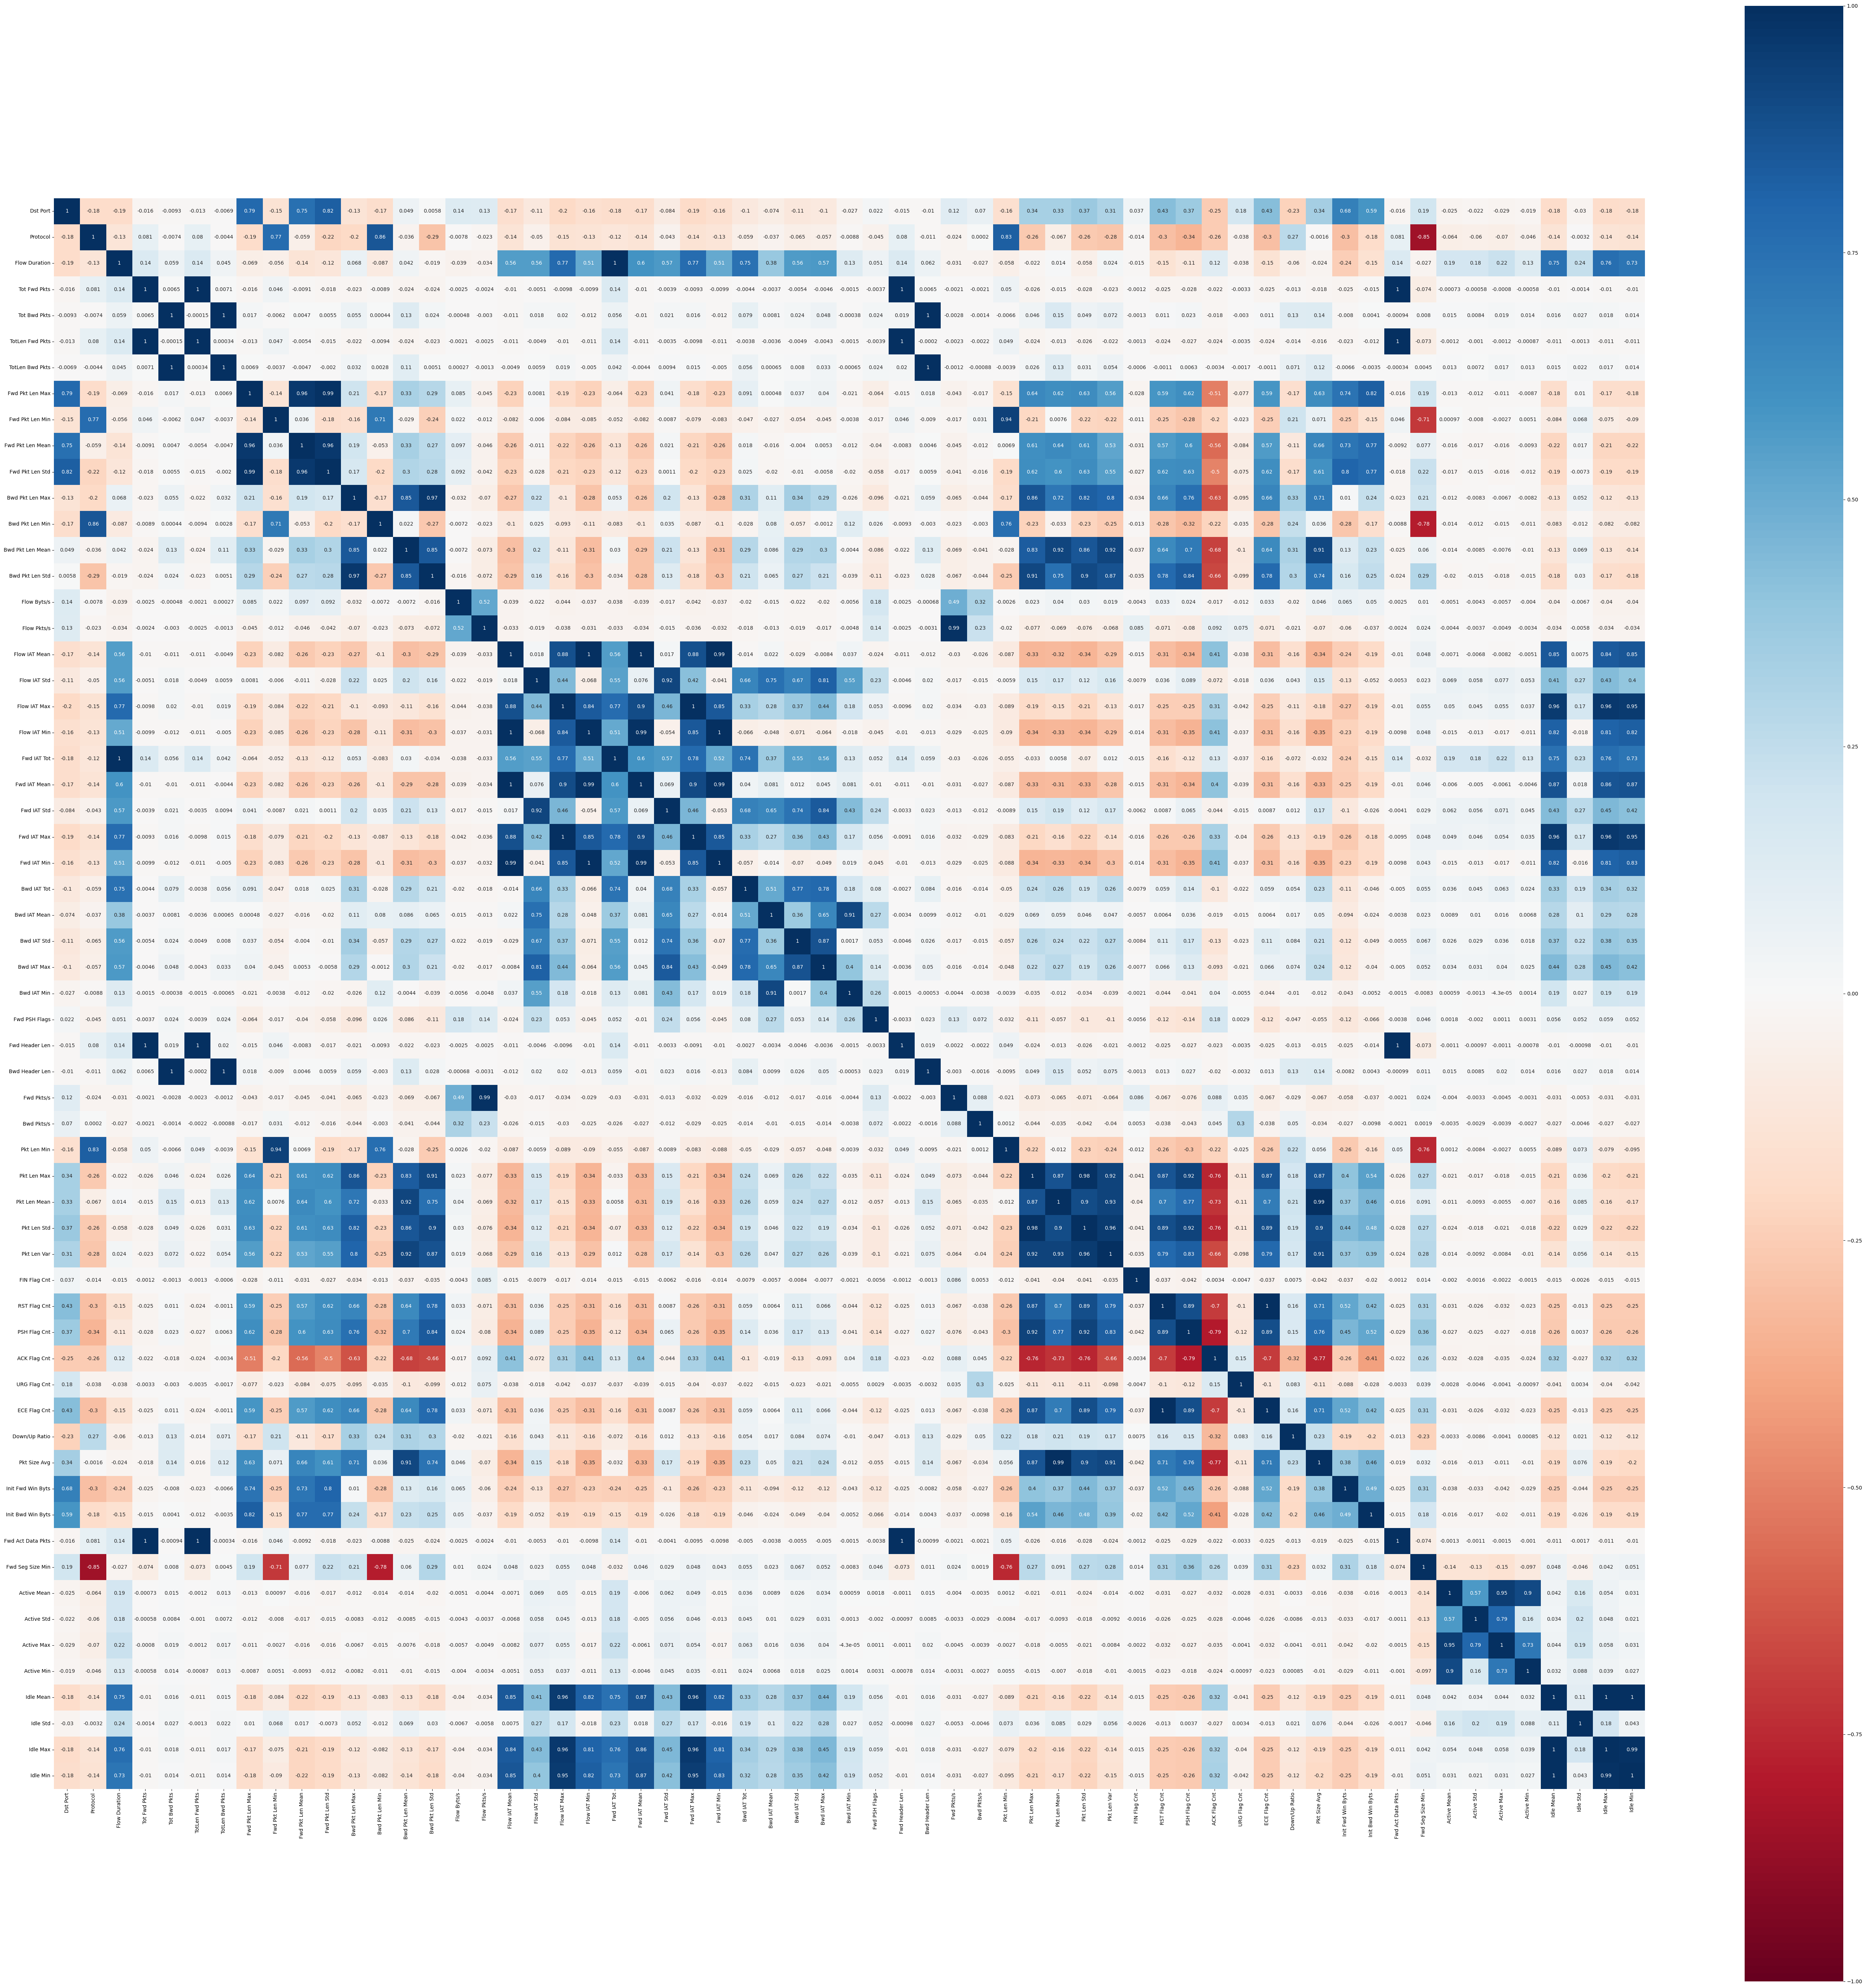

In [24]:
from matplotlib import pyplot as plt
import seaborn as sns

# pearson correlation heatmap
plt.figure(figsize=(70, 70))
corr = df_all.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='RdBu', vmin=-1, vmax=1, square=True) # annot=True
plt.show()

In [25]:
%%time
correlated_col = set()
is_correlated = [True] * len(corr.columns)
threshold = 0.90
for i in range (len(corr.columns)):
    if(is_correlated[i]):
        for j in range(i):
            if (np.abs(corr.iloc[i, j]) >= threshold) and (is_correlated[j]):
                colname = corr.columns[j]
                is_correlated[j]=False
                correlated_col.add(colname)

print(correlated_col)
print(len(correlated_col))

{'Flow IAT Max', 'Fwd Pkt Len Min', 'Flow IAT Mean', 'Fwd Pkt Len Max', 'Fwd IAT Mean', 'Bwd IAT Mean', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Bwd Pkt Len Std', 'Pkt Len Std', 'Flow IAT Std', 'Idle Mean', 'Bwd Pkt Len Mean', 'Fwd Header Len', 'RST Flag Cnt', 'Tot Fwd Pkts', 'Active Mean', 'Idle Max', 'Fwd Pkt Len Mean', 'Flow Pkts/s', 'Tot Bwd Pkts', 'Flow Duration', 'Pkt Len Var', 'Bwd Pkt Len Max', 'Pkt Len Mean', 'Flow IAT Min', 'Pkt Len Max', 'Fwd IAT Max'}
28
CPU times: user 44.6 ms, sys: 1.1 ms, total: 45.7 ms
Wall time: 44.4 ms


In [26]:
%%time
df_all.drop(correlated_col, axis=1, inplace=True)
print (df_all.shape)

(1874048, 35)
CPU times: user 150 ms, sys: 998 µs, total: 151 ms
Wall time: 149 ms


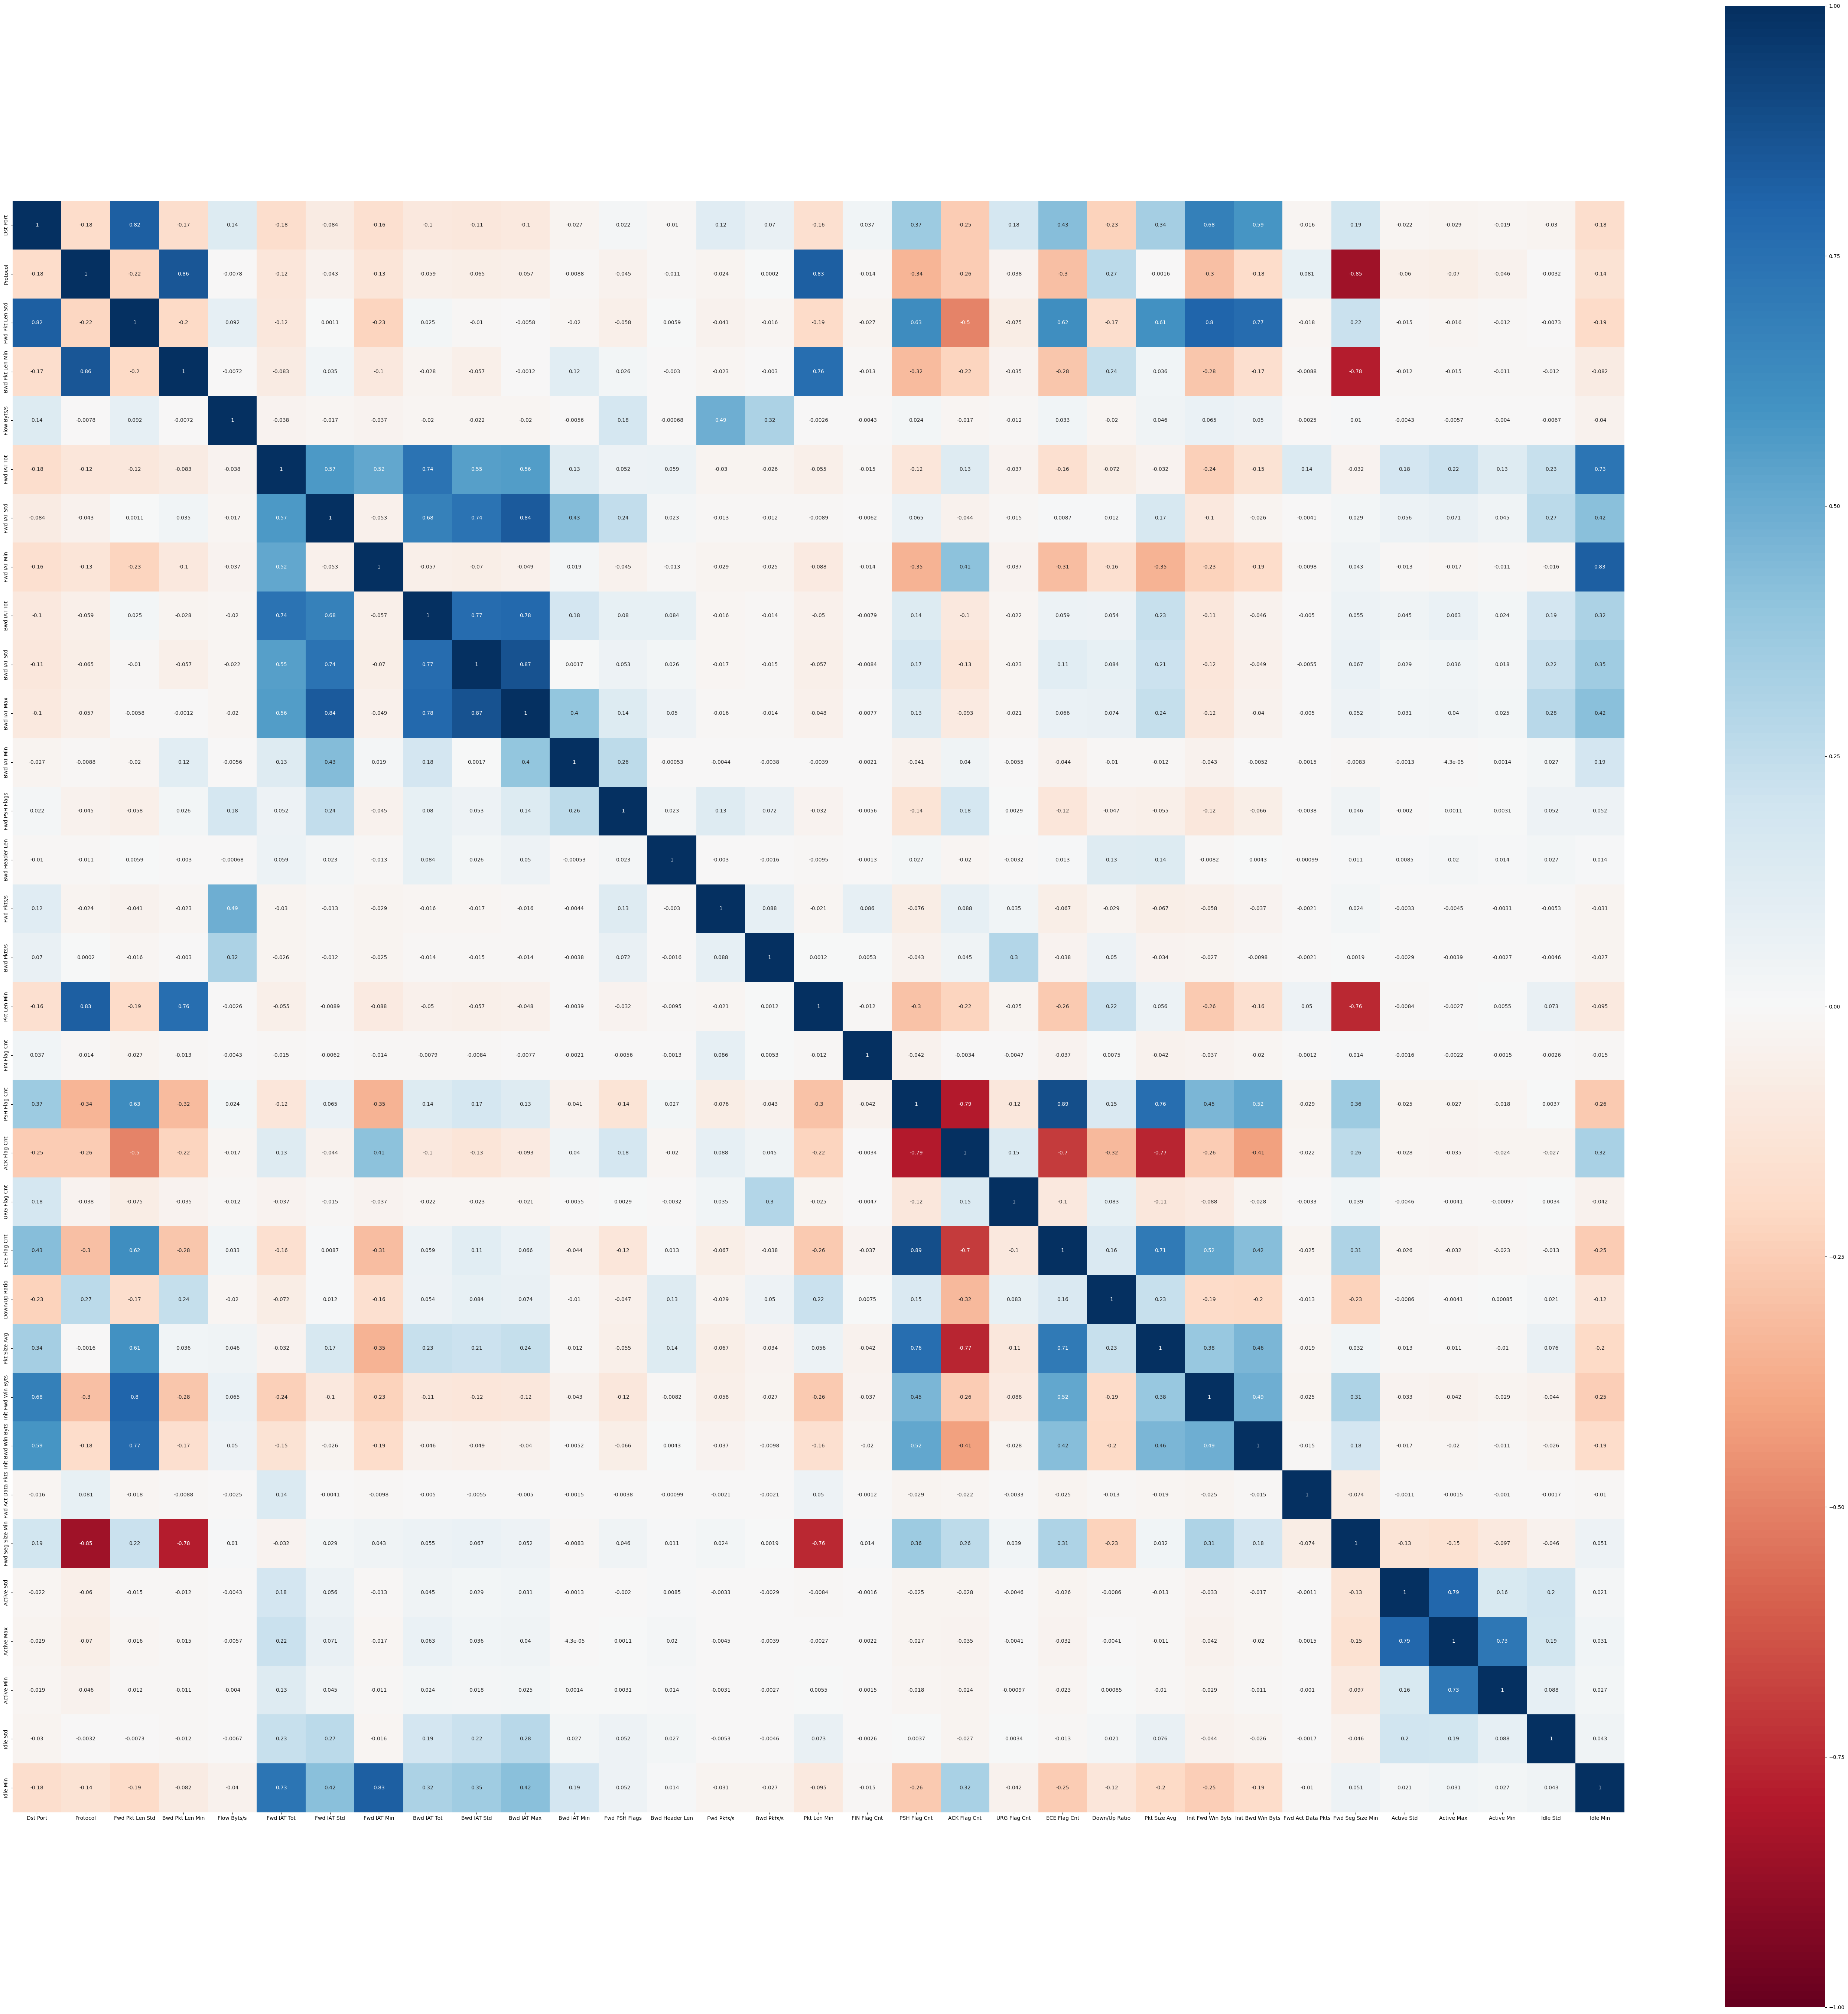

CPU times: user 9.74 s, sys: 221 ms, total: 9.96 s
Wall time: 9.96 s


In [27]:
%%time
# pearson correlation heatmap
plt.figure(figsize=(70, 70))
corr = df_all.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='RdBu', vmin=-1, vmax=1, square=True) # annot=True
plt.show()

In [28]:
label_col = "Label"
feature_cols = list(df_all.columns)
feature_cols

['Dst Port',
 'Protocol',
 'Fwd Pkt Len Std',
 'Bwd Pkt Len Min',
 'Flow Byts/s',
 'Fwd IAT Tot',
 'Fwd IAT Std',
 'Fwd IAT Min',
 'Bwd IAT Tot',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Bwd Header Len',
 'Fwd Pkts/s',
 'Bwd Pkts/s',
 'Pkt Len Min',
 'FIN Flag Cnt',
 'PSH Flag Cnt',
 'ACK Flag Cnt',
 'URG Flag Cnt',
 'ECE Flag Cnt',
 'Down/Up Ratio',
 'Pkt Size Avg',
 'Init Fwd Win Byts',
 'Init Bwd Win Byts',
 'Fwd Act Data Pkts',
 'Fwd Seg Size Min',
 'Active Std',
 'Active Max',
 'Active Min',
 'Idle Std',
 'Idle Min',
 'Threat',
 'Label']

In [29]:
label_col = 'Label'

feature_cols.remove("Threat")
feature_cols.remove(label_col)

In [30]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df_all, test_size=0.2, random_state=2, shuffle=True, stratify=df_all[label_col])

del df_all 

In [31]:
from sklearn.preprocessing import RobustScaler, MinMaxScaler

minmax_scaler = MinMaxScaler()
train_df[feature_cols] = minmax_scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = minmax_scaler.transform(test_df[feature_cols])

In [32]:
order_label_list = list(np.unique(train_df[label_col]))
order_label_list

['Benign', 'DDoS attack']

In [33]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight('balanced',
                                                 classes=order_label_list,
                                                 y=train_df[label_col].values)

class_weights = {k: v for k,v in enumerate(class_weights)}
class_weights

{0: 1.0, 1: 1.0}

In [34]:
import json 
    
with open("class_weights.json", "w") as outfile: 
    json.dump(class_weights, outfile)

In [35]:
import json 

label_dict = {v:v for v in order_label_list}
    
with open("label_dict.json", "w") as outfile: 
    json.dump(label_dict, outfile)


    label_dict

In [36]:
y_train = [order_label_list.index(k) for k in train_df[label_col]]
y_test = [order_label_list.index(k) for k in test_df[label_col]]

In [37]:
train_df[feature_cols+[label_col]].to_csv("train_df.csv",index=False)
test_df[feature_cols+[label_col]].to_csv("test_df.csv",index=False)

In [38]:
del train_df, test_df

In [39]:
import json

with open('label_dict.json') as json_file:
    label_dict = json.load(json_file)

label_dict

{'Benign': 'Benign', 'DDoS attack': 'DDoS attack'}

In [40]:
import json

with open('class_weights.json') as json_file:
    class_weights = json.load(json_file)

class_weights

{'0': 1.0, '1': 1.0}

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import optimizers
from tensorflow.keras import backend as K
import logging.config
from gym import  spaces
import gym
import json
import sys
import time

In [42]:
class data_cls:
    def __init__(self, train_test, attack_map, **kwargs):
        self.train_test = train_test
        
        if self.train_test == 'train':
            self.train_path = "train_df.csv"
        else:
            self.test_path = "test_df.csv"

        self.attack_map =   attack_map 
        self.attack_types = list(attack_map.keys())
        
        self.loaded = False
        
    
    def get_batch(self, batch_size=100):
        
        if self.loaded is False:
            self._load_df()
            
        indexes = list(range(self.index,self.index+batch_size))    
        if max(indexes)>self.data_shape[0]-1:
            dif = max(indexes)-self.data_shape[0]
            indexes[len(indexes)-dif-1:len(indexes)] = list(range(dif+1))
            self.index=batch_size-dif
            batch = self.df.iloc[indexes]
        else: 
            batch = self.df.iloc[indexes]
            self.index += batch_size    
        
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        del(batch[label_col])
            
        return np.array(batch),labels
    
    def get_full(self):

        self._load_df()
        
        batch = self.df
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        
        del(batch[label_col])
        
        return np.array(batch), labels
    
    def get_shape(self):
        if self.loaded is False:
            self._load_df()
        
        self.data_shape = self.df.shape
        return self.data_shape
    
    def _load_df(self):
        if self.train_test == 'train':
            self.df = pd.read_csv(self.train_path) 
        else:
            self.df = pd.read_csv(self.test_path)
            
        self.index=np.random.randint(0,self.df.shape[0]-1,dtype=np.int32)
        self.loaded = True

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [43]:
class NetworkClassificationEnv(gym.Env, data_cls):
    def __init__(self,train_test, attack_map, **kwargs):
        data_cls.__init__(self,train_test, attack_map,**kwargs)
        self.data_shape = self.get_shape()
        self.batch_size = kwargs.get('batch_size', 1) 
        self.fails_episode = kwargs.get('fails_episode', 10) 
        
        # Gym spaces
        self.action_space = spaces.Discrete(len(self.attack_types))
        self.observation_space = spaces.Discrete(self.data_shape[0])
        
        self.observation_len = self.data_shape[1]-1
        
        self.counter = 0

    def _update_state(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        

    def reset(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        self.counter = 0
        
        return self.states
    def _get_rewards(self,actions):
        self.reward = 0
        if actions == self.labels:
            self.reward = 1
        else: 
            self.counter += 1

    def step(self,actions):
        self._get_rewards(actions)
            
        self._update_state()

        if self.counter >= self.fails_episode:
            self.done = True
        else:
            self.done = False
            
        return self.states, self.reward, self.done

In [44]:
import tensorflow as tf
from tensorflow.keras import backend as K

@tf.keras.utils.register_keras_serializable(package="Custom", name="huber_loss")
def huber_loss(y_true, y_pred, clip_value=1.0):
    assert clip_value > 0.0, "clip_value must be positive."

    x = y_true - y_pred
    
    # Handle the case when clip_value is infinity
    if np.isinf(clip_value):
        return 0.5 * tf.square(x)

    # Define condition for the quadratic part
    condition = tf.abs(x) < clip_value

    # Compute squared and linear losses
    squared_loss = 0.5 * tf.square(x)
    linear_loss = clip_value * (tf.abs(x) - 0.5 * clip_value)

    # Use TensorFlow's conditional logic to return the appropriate loss
    return tf.where(condition, squared_loss, linear_loss)


In [45]:
class QNetwork():
    def __init__(self,obs_size,num_actions, hidden_dense_layer_dict = {"Dense_1": {"Size": 100}}, learning_rate=0.001):
        self.model = Sequential()
        
        self.model.add(Input(shape=(obs_size,)))

        for key, value in hidden_dense_layer_dict.items():
            self.model.add(Dense(value["Size"], activation='relu', name=key))

        self.model.add(Dense(num_actions))
        
        optimizer = optimizers.Adam(learning_rate)
        self.model.compile(loss=huber_loss,optimizer=optimizer)

    def predict(self,state,batch_size=1):
        return self.model.predict(state,batch_size=batch_size, verbose=0)

    def update(self, states, q):
        loss = self.model.train_on_batch(states, q, class_weight=class_weights)
        return loss

class Policy:
    def __init__(self, num_actions, estimator):
        self.num_actions = num_actions
        self.estimator = estimator
class Epsilon_greedy(Policy):
    def __init__(self,estimator ,num_actions,epsilon,decay_rate, epoch_length):
        Policy.__init__(self, num_actions, estimator)
        self.name = "Epsilon Greedy"
        if (epsilon is None or epsilon < 0 or epsilon > 1):
            print("EpsilonGreedy: Invalid value of epsilon", flush = True)
            sys.exit(0)
        self.epsilon = epsilon
        self.step_counter = 0
        self.epoch_length = epoch_length
        self.decay_rate = decay_rate
        self.epsilon_decay = True
        
    def get_actions(self,states):
        if np.random.rand() <= self.epsilon:
            actions = np.random.randint(0, self.num_actions,states.shape[0])
        else:
            self.Q = self.estimator.predict(states,states.shape[0])

            actions = []
            for row in range(self.Q.shape[0]):
                best_actions = np.argwhere(self.Q[row] == np.amax(self.Q[row]))
                actions.append(best_actions[np.random.choice(len(best_actions))].item())
        self.step_counter += 1 

        if self.epsilon_decay:
            if self.step_counter % self.epoch_length == 0:
                self.epsilon = max(.01, self.epsilon * self.decay_rate**self.step_counter)
            
        return actions

class Agent(object):   
    def __init__(self, actions, obs_size, policy="EpsilonGreedy", **kwargs):
        
        self.actions = actions
        self.num_actions = len(actions)
        self.obs_size = obs_size
        
        self.epsilon = kwargs.get('epsilon', 1)
        self.gamma = kwargs.get('gamma', 0.001)
        self.minibatch_size = kwargs.get('minibatch_size', 2)
        self.epoch_length = kwargs.get('epoch_length', 100)
        self.decay_rate = kwargs.get('decay_rate',0.99)
        self.exp_rep = kwargs.get('exp_rep',True)
        
        if self.exp_rep:
            self.memory = ReplayMemory(self.obs_size, kwargs.get('mem_size', 10))
        self.ddqn_time = 100
        self.ddqn_update = self.ddqn_time

        self.model_network = QNetwork(self.obs_size, 
                                      self.num_actions,
                                      kwargs.get('hidden_dense_layer_dict', {"Dense_1": {"Size": 100}}),
                                      kwargs.get('learning_rate', 0.001))
        
        self.target_model_network = QNetwork(self.obs_size, self.num_actions,
                                             kwargs.get('hidden_dense_layer_dict', {"Dense_1": {"Size": 100}}),
                                             kwargs.get('learning_rate', 0.001))
        
        self.target_model_network.model.set_weights(self.model_network.model.get_weights()) 
        
        if policy == "EpsilonGreedy":
            self.policy = Epsilon_greedy(self.model_network,
                                         len(actions),
                                         self.epsilon,
                                         self.decay_rate,
                                         self.epoch_length)
        
    def act(self,states):
        actions = self.policy.get_actions(states)
        return actions
    
    def learn(self, states, actions,next_states, rewards, done):
        if self.exp_rep:
            self.memory.observe(states, actions, rewards, done)
        else:
            self.states = states
            self.actions = actions
            self.next_states = next_states
            self.rewards = rewards
            self.done = done


    def update_model(self):
        if self.exp_rep:
            (states, actions, rewards, next_states, done) = self.memory.sample_minibatch(self.minibatch_size)
        else:
            states = self.states
            rewards = self.rewards
            next_states = self.next_states
            actions = self.actions
            done = self.done
            
        next_actions = []
        Q_prime = self.model_network.predict(next_states,self.minibatch_size)

        for row in range(Q_prime.shape[0]):
            best_next_actions = np.argwhere(Q_prime[row] == np.amax(Q_prime[row]))
            next_actions.append(best_next_actions[np.random.choice(len(best_next_actions))].item())
        sx = np.arange(len(next_actions))

        Q = self.target_model_network.predict(states,self.minibatch_size)

        targets = rewards.reshape(Q[sx,actions].shape) + \
                  self.gamma * Q_prime[sx,next_actions] * \
                  (1-done.reshape(Q[sx,actions].shape))   
        Q[sx,actions] = targets  
        
        loss = self.model_network.model.train_on_batch(states,Q)
        
        self.ddqn_update -= 1
        if self.ddqn_update == 0:
            self.ddqn_update = self.ddqn_time
            self.target_model_network.model.set_weights(self.model_network.model.get_weights()) 
        
        return loss    
    
        
class ReplayMemory(object):
    def __init__(self, observation_size, max_size):
        self.observation_size = observation_size
        self.num_observed = 0
        self.max_size = max_size
        self.samples = {
                 'obs'      : np.zeros(self.max_size * 1 * self.observation_size,
                                       dtype=np.float32).reshape(self.max_size, self.observation_size),
                 'action'   : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
                 'reward'   : np.zeros(self.max_size * 1).reshape(self.max_size, 1),
                 'terminal' : np.zeros(self.max_size * 1, dtype=np.int16).reshape(self.max_size, 1),
               }

    def observe(self, state, action, reward, done):
        index = self.num_observed % self.max_size
        self.samples['obs'][index, :] = state
        self.samples['action'][index, :] = action
        self.samples['reward'][index, :] = reward
        self.samples['terminal'][index, :] = done

        self.num_observed += 1

    def sample_minibatch(self, minibatch_size):
        max_index = min(self.num_observed, self.max_size) - 1
        sampled_indices = np.random.randint(max_index, size=minibatch_size)

        s      = np.asarray(self.samples['obs'][sampled_indices, :], dtype=np.float32)
        s_next = np.asarray(self.samples['obs'][sampled_indices+1, :], dtype=np.float32)

        a      = self.samples['action'][sampled_indices].reshape(minibatch_size)
        r      = self.samples['reward'][sampled_indices].reshape((minibatch_size, 1))
        done   = self.samples['terminal'][sampled_indices].reshape((minibatch_size, 1))

        return (s, a, r, s_next, done)

In [46]:
import shutil

if os.path.isdir("models"):
    shutil.rmtree("models", ignore_errors=False, onerror=None)

In [47]:
label_col = 'Label'

In [48]:
model_path = "models"

epsilon = 1  

batch_size = 1

minibatch_size = 100
exp_rep = True

iterations_episode = 100

decay_rate = 0.99
gamma = 0.001

learning_rate = 0.001

hidden_dense_layer_dict = {"Dense_2": {"Size": 64},
                           "Dense_3": {"Size": 32}
                           }

env = NetworkClassificationEnv('train',
                                label_dict,
                                batch_size = batch_size,
                                iterations_episode = iterations_episode)
# num_episodes = int(env.data_shape[0]/(iterations_episode)/10)
num_episodes = 10
valid_actions = list(range(len(env.attack_types)))
num_actions = len(valid_actions)

obs_size = env.observation_len

agent = Agent(valid_actions,
              obs_size,
              "EpsilonGreedy",
              learning_rate = learning_rate,
              epoch_length = iterations_episode,
              epsilon = epsilon,
              decay_rate = decay_rate,
              gamma = gamma,
              hidden_dense_layer_dict = hidden_dense_layer_dict,
              minibatch_size=minibatch_size,
              mem_size = 10000,
              exp_rep=exp_rep)    


# Statistics
reward_chain = []
loss_chain = []

In [49]:
# Main loop
for epoch in range(num_episodes):
    start_time = time.time()
    loss = 0.
    total_reward_by_episode = 0

    states = env.reset()

    done = False

    true_labels = np.zeros(len(env.attack_types))
    estimated_labels = np.zeros(len(env.attack_types))

    for i_iteration in range(iterations_episode):
        actions = agent.act(states)

        estimated_labels[actions] += 1
        true_labels[env.labels] += 1

        next_states, reward, done = env.step(actions)
        agent.learn(states, actions, next_states, reward, done)

        if exp_rep and epoch*iterations_episode + i_iteration >= minibatch_size:
            loss += agent.update_model()
        elif not exp_rep:
            loss += agent.update_model()

        update_end_time = time.time()

        states = next_states

        total_reward_by_episode += np.sum(reward, dtype=np.int32)

    reward_chain.append(total_reward_by_episode)    
    loss_chain.append(loss) 


    end_time = time.time()
    print("\r|Epoch {:03d}/{:03d} | Loss {:4.4f} |" 
            "Tot reward in ep {:03d}| time: {:2.2f}|"
            .format(epoch, num_episodes 
            ,loss, total_reward_by_episode,(end_time-start_time)))
    print("\r|Estimated: {}|Labels: {}".format(estimated_labels,true_labels))

if not os.path.exists('models'):
    os.makedirs('models')
    
agent.model_network.model.save_weights("models/DDQN_model.weights.h5", overwrite=True)

with open("models/DDQN_model.json", "w") as outfile:
    json.dump(agent.model_network.model.to_json(), outfile)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


|Epoch 000/010 | Loss 0.0000 |Tot reward in ep 043| time: 0.15|
|Estimated: [52. 48.]|Labels: [55. 45.]
|Epoch 001/010 | Loss 7.9656 |Tot reward in ep 075| time: 26.65|
|Estimated: [48. 52.]|Labels: [45. 55.]
|Epoch 002/010 | Loss 5.5966 |Tot reward in ep 093| time: 27.16|
|Estimated: [46. 54.]|Labels: [49. 51.]
|Epoch 003/010 | Loss 3.9394 |Tot reward in ep 095| time: 28.59|
|Estimated: [43. 57.]|Labels: [48. 52.]
|Epoch 004/010 | Loss 3.0512 |Tot reward in ep 090| time: 29.22|
|Estimated: [38. 62.]|Labels: [46. 54.]
|Epoch 005/010 | Loss 2.5323 |Tot reward in ep 097| time: 29.69|
|Estimated: [51. 49.]|Labels: [54. 46.]
|Epoch 006/010 | Loss 2.1828 |Tot reward in ep 097| time: 29.73|
|Estimated: [45. 55.]|Labels: [48. 52.]
|Epoch 007/010 | Loss 1.9259 |Tot reward in ep 095| time: 31.18|
|Estimated: [47. 53.]|Labels: [52. 48.]
|Epoch 008/010 | Loss 1.7213 |Tot reward in ep 096| time: 32.14|
|Estimated: [45. 55.]|Labels: [47. 53.]
|Epoch 009/010 | Loss 1.5554 |Tot reward in ep 098| time

In [50]:
import os

# Check if the weights and model files exist
weights_path = "models/DDQN_model.weights.h5"
json_path = "models/DDQN_model.json"

if os.path.exists(weights_path) and os.path.exists(json_path):
    print("Model files exist.")
else:
    print("Model files are missing.")

Model files exist.


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


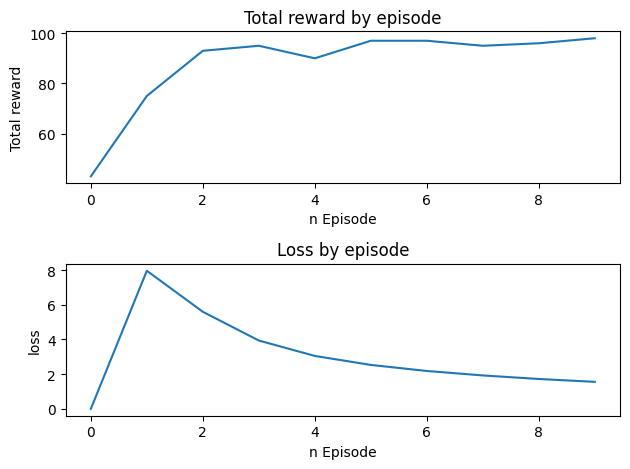

In [51]:
plt.figure(1)
plt.subplot(211)
plt.plot(np.arange(len(reward_chain)),reward_chain)
plt.title('Total reward by episode')
plt.xlabel('n Episode')
plt.ylabel('Total reward')
''
plt.subplot(212)
plt.plot(np.arange(len(loss_chain)),loss_chain)
plt.title('Loss by episode')
plt.xlabel('n Episode')
plt.ylabel('loss')
plt.tight_layout()
#plt.show()


if not os.path.exists('results'):
    os.makedirs('results')
    
plt.savefig('results/train_type_improved.eps', format='eps', dpi=1000)

In [52]:
import json
import numpy as np
import pandas as pd
from tensorflow.keras.models import model_from_json
import matplotlib.pyplot as plt

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix

In [53]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [54]:
with open("models/DDQN_model.json", "r") as jfile:
    model = model_from_json(json.load(jfile))
model.load_weights("models/DDQN_model.weights.h5")


model.compile(loss=huber_loss, optimizer="sgd")

env = NetworkClassificationEnv('test', label_dict) 

In [55]:
 total_reward = 0
    
true_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_correct_labels = np.zeros(len(env.attack_types),dtype=int)

states, labels = env.get_full()
q = model.predict(states)
actions = np.argmax(q, axis=1)        


labs, true_labels = np.unique(labels, return_counts=True)

for indx,a in enumerate(actions):
    estimated_labels[a] +=1              
    if a == labels[indx]:
        total_reward += 1
        estimated_correct_labels[a] += 1


Accuracy = estimated_correct_labels / true_labels
Mismatch = estimated_labels - true_labels
print('\r\nTotal reward: {} | Number of samples: {} | Accuracy = {}%'.format(total_reward,
      len(states),float(100*total_reward/len(states))))
outputs_df = pd.DataFrame(index = env.attack_types,columns = ["Estimated","Correct","Total","Acuracy"])
for indx,att in enumerate(env.attack_types):
    outputs_df.iloc[indx].Estimated = estimated_labels[indx]
    outputs_df.iloc[indx].Correct = estimated_correct_labels[indx]
    outputs_df.iloc[indx].Total = true_labels[indx]
    outputs_df.iloc[indx].Acuracy = Accuracy[indx]*100
    outputs_df.iloc[indx].Mismatch = abs(Mismatch[indx])

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


11713/11713 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step

Total reward: 370363 | Number of samples: 374810 | Accuracy = 98.81353218964276%


In [56]:
outputs_df

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Estimated,Correct,Total,Acuracy
Benign,183722,183340,187405,97.830901
DDoS attack,191088,187023,187405,99.796163


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


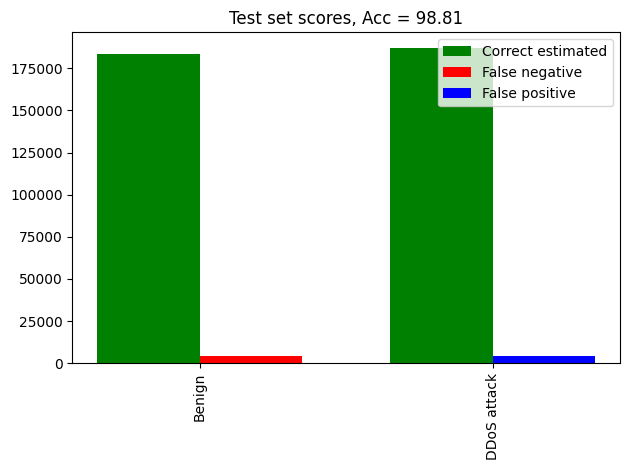

<Figure size 640x480 with 0 Axes>

In [57]:
fig, ax = plt.subplots()
width = 0.35
pos = np.arange(len(true_labels))
p1 = plt.bar(pos, estimated_correct_labels,width,color='g')
p1 = plt.bar(pos+width,
             (np.abs(estimated_correct_labels-true_labels)),width,
             color='r')
p2 = plt.bar(pos+width,np.abs(estimated_labels-estimated_correct_labels),width,
             bottom=(np.abs(estimated_correct_labels-true_labels)),
             color='b')


ax.set_xticks(pos+width/2)
ax.set_xticklabels(env.attack_types,rotation='vertical')

ax.set_title('Test set scores, Acc = {:.2f}'.format(100*total_reward/len(states)))
plt.legend(('Correct estimated','False negative','False positive'))
plt.tight_layout()
plt.show()
plt.savefig('results/ADFA_DDQN.svg', format='svg', dpi=1000)

Performance measures on Test data
Accuracy =  0.9881
F1 =  0.9881
Precision_score =  0.9883
recall_score =  0.9881
Normalized confusion matrix
[[0.98 0.02]
 [0.   1.  ]]


<Figure size 640x480 with 0 Axes>

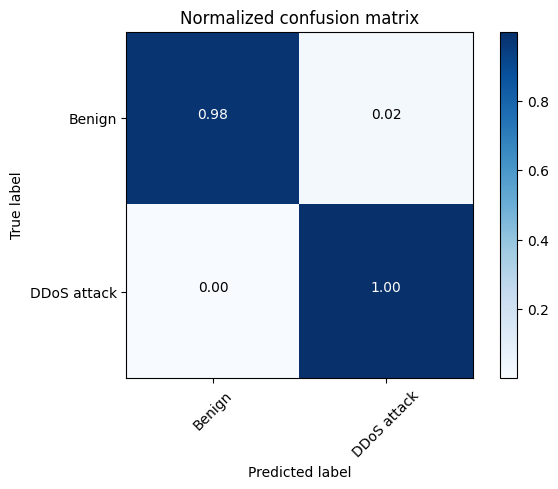

In [58]:
aggregated_data_test =labels

print('Performance measures on Test data')
print('Accuracy =  {:.4f}'.format(accuracy_score( aggregated_data_test,actions)))
print('F1 =  {:.4f}'.format(f1_score(aggregated_data_test,actions, average='weighted')))
print('Precision_score =  {:.4f}'.format(precision_score(aggregated_data_test,actions, average='weighted')))
print('recall_score =  {:.4f}'.format(recall_score(aggregated_data_test,actions, average='weighted')))

cnf_matrix = confusion_matrix(aggregated_data_test,actions)
np.set_printoptions(precision=2)
plt.figure()
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=env.attack_types, normalize=True,
                      title='Normalized confusion matrix')




plt.savefig('results/confusion_matrix_DDQN_model.svg', format='svg', dpi=1000)

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


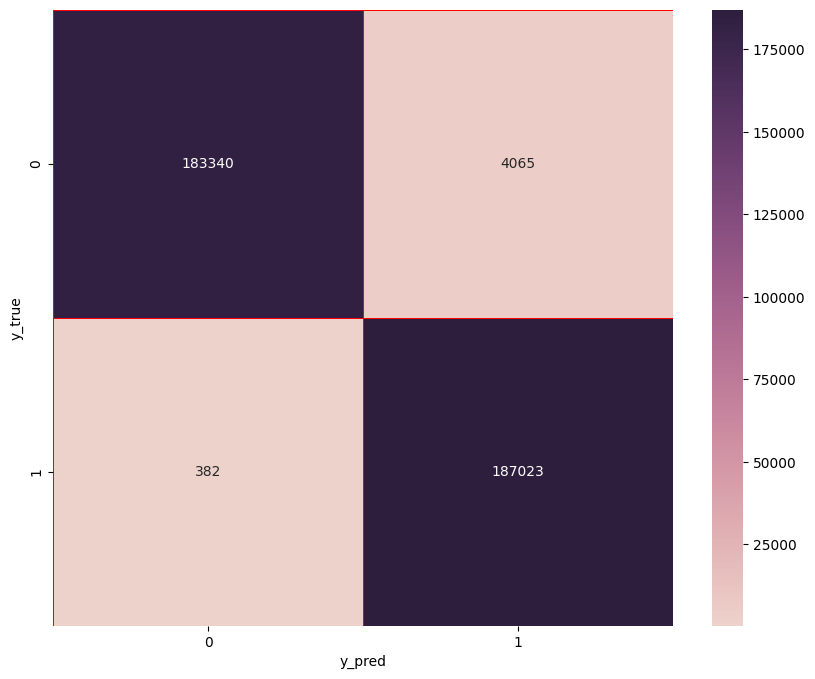

In [59]:

cm=confusion_matrix(aggregated_data_test,actions)
f,ax=plt.subplots(figsize=(10,8))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax,cmap=sns.cubehelix_palette(as_cmap=True))
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()